# Baselines and models

**Primary outcome:** at the 4 PM issue time, does Delhi AQI reach 301 exactly 48 hours later, conditional on starting AQI below 301? The any-hour +48h outcome is secondary; exact and any-hour +24h/+72h outcomes are exploratory secondary analyses. Onset models exclude rows already at AQI 301 or above. A separate post-hoc secondary task predicts clearance below 301 at +48h from starts already at 301 or above.

This notebook evaluates the locked compact logistic model and reports the small 2025–26 holdout as-is. The inputs are observed measurements at the issue time; their operational reporting latency has not been assessed. Calendar-year 2026 source coverage is partial through September.


In [1]:
import numpy as np
import pandas as pd

daily_4pm = pd.read_csv("../processed_data/daily_4pm_winter_labels.csv",
                        index_col=0, parse_dates=True)

# Days since 1 November of each winter.
start = pd.DatetimeIndex(pd.to_datetime(
    pd.DataFrame({"year": daily_4pm["season"].astype(int).values,
                  "month": 11, "day": 1})))
daily_4pm["season_day"] = (daily_4pm.index - start).days

# Whole-winter splits. Keep test rows untouched until final evaluation.
train_rows = daily_4pm["season"].isin([2018, 2019, 2021, 2022, 2023])
val_rows = daily_4pm["season"].eq(2024)
test_rows = daily_4pm["season"].eq(2025)

# Evaluate exact-endpoint and any-hour outcomes separately because their known rows differ by horizon.
labels = ["target_24h_301", "target_48h_301", "target_72h_301",
          "target_any_24h_301", "target_any_48h_301", "target_any_72h_301"]

# Load onset timestamps for later event-level evaluation.
onsets = pd.read_csv("../processed_data/winter_onsets.csv",
                     parse_dates=["onset_time"])["onset_time"]

# Check that Notebook 02 saved every horizon/outcome label and the 2025-26 winter.
assert all(label in daily_4pm for label in labels), "Notebook 02 is missing a requested label"
assert daily_4pm["season"].max() == 2025, "Notebook 02 output does not include winter 2025-26"
print("Known forecast rows by outcome:", daily_4pm[labels].notna().sum().to_dict())

def rows_for(label, split):
    """Keep split rows with known outcomes and a starting AQI below 301."""
    usable = split & daily_4pm["AQI"].lt(301) & daily_4pm[label].notna()
    return daily_4pm.loc[usable]

# Exclude labels, future measurements, and bookkeeping from numeric inputs.
leaky = [c for c in daily_4pm.columns
         if c.startswith(("target_", "AQI_at_plus", "AQI_change")) or "ahead" in c]
bookkeeping = ["season", "starting_aqi_band", "AQI_source", "AQI_review_status"]
# TOT-RF is a cumulative counter with implausible values; do not use it as a predictor.
excluded_measurements = ["TOT-RF (mm)"]
feature_cols = [c for c in daily_4pm.columns
                if c not in leaky + bookkeeping + excluded_measurements
                and pd.api.types.is_numeric_dtype(daily_4pm[c])]

print("Rows:", daily_4pm.shape[0])
print("Train / val / test rows:", int(train_rows.sum()), int(val_rows.sum()), int(test_rows.sum()))
print("Known onset timestamps:", len(onsets))
print("Feature columns (", len(feature_cols), "):", feature_cols)

Known forecast rows by outcome: {'target_24h_301': 338, 'target_48h_301': 338, 'target_72h_301': 337, 'target_any_24h_301': 327, 'target_any_48h_301': 319, 'target_any_72h_301': 312}
Rows: 842
Train / val / test rows: 602 120 120
Known onset timestamps: 68
Feature columns ( 24 ): ['PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO (µg/m³)', 'NO2 (µg/m³)', 'NOx (ppb)', 'NH3 (µg/m³)', 'SO2 (µg/m³)', 'CO (mg/m³)', 'Ozone (µg/m³)', 'Benzene (µg/m³)', 'Toluene (µg/m³)', 'AT (°C)', 'RH (%)', 'WS (m/s)', 'WD (deg)', 'RF (mm)', 'SR (W/mt2)', 'BP (mmHg)', 'VWS (m/s)', 'AQI', 'AQI_24h', 'AQI_48h', 'AQI_72h', 'season_day']


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

def train_and_score(model, cols, name):
    """Train on the training winters, then score on the validation winter."""
    for label in labels:
        tr, va = rows_for(label, train_rows), rows_for(label, val_rows)
        model.fit(tr[cols], tr[label])                   # learn from training winters
        p = model.predict_proba(va[cols])[:, 1]          # risk score for each validation day
        ref = brier_score_loss(va[label], np.full(len(va), tr[label].mean()))
        print(f"{name} | {label}")
        print(f"   average precision {average_precision_score(va[label], p):.2f}"
              f"  (reference {va[label].mean():.2f})")
        print(f"   ROC AUC           {roc_auc_score(va[label], p):.2f}  (coin flip 0.50)")
        print(f"   Brier             {brier_score_loss(va[label], p):.3f}"
              f"  (reference {ref:.3f}, lower is better)")
    return model

model_1 = train_and_score(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    ["AQI"], "Model 1: Logistic, AQI only")

# Peek inside: how much does the risk rise as AQI goes up?
coef = model_1.named_steps["logisticregression"].coef_[0][0]
print("\nAQI coefficient:", round(coef, 2), "(positive = higher AQI means higher risk)")

Model 1: Logistic, AQI only | target_24h_301
   average precision 0.40  (reference 0.12)
   ROC AUC           0.80  (coin flip 0.50)
   Brier             0.104  (reference 0.112, lower is better)
Model 1: Logistic, AQI only | target_48h_301
   average precision 0.51  (reference 0.22)
   ROC AUC           0.73  (coin flip 0.50)
   Brier             0.165  (reference 0.182, lower is better)
Model 1: Logistic, AQI only | target_72h_301
   average precision 0.50  (reference 0.25)
   ROC AUC           0.70  (coin flip 0.50)
   Brier             0.184  (reference 0.200, lower is better)
Model 1: Logistic, AQI only | target_any_24h_301
   average precision 0.54  (reference 0.16)
   ROC AUC           0.83  (coin flip 0.50)
   Brier             0.113  (reference 0.138, lower is better)
Model 1: Logistic, AQI only | target_any_48h_301
   average precision 0.57  (reference 0.28)
   ROC AUC           0.76  (coin flip 0.50)
   Brier             0.179  (reference 0.220, lower is better)
Model 1: Log

In [3]:
model_2 = train_and_score(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    ["AQI", "season_day"], "Model 2: Logistic, AQI + time of winter")

# Peek inside: the model now has two coefficients, in the order of the columns
coefs = model_2.named_steps["logisticregression"].coef_[0]
print("\nCoefficients (AQI, season_day):", coefs.round(2))

Model 2: Logistic, AQI + time of winter | target_24h_301
   average precision 0.35  (reference 0.12)
   ROC AUC           0.83  (coin flip 0.50)
   Brier             0.099  (reference 0.112, lower is better)
Model 2: Logistic, AQI + time of winter | target_48h_301
   average precision 0.41  (reference 0.22)
   ROC AUC           0.78  (coin flip 0.50)
   Brier             0.160  (reference 0.182, lower is better)
Model 2: Logistic, AQI + time of winter | target_72h_301
   average precision 0.42  (reference 0.25)
   ROC AUC           0.76  (coin flip 0.50)
   Brier             0.173  (reference 0.200, lower is better)
Model 2: Logistic, AQI + time of winter | target_any_24h_301
   average precision 0.47  (reference 0.16)
   ROC AUC           0.83  (coin flip 0.50)
   Brier             0.109  (reference 0.138, lower is better)
Model 2: Logistic, AQI + time of winter | target_any_48h_301
   average precision 0.52  (reference 0.28)
   ROC AUC           0.81  (coin flip 0.50)
   Brier       

In [4]:
from sklearn.impute import SimpleImputer

all_features = [c for c in feature_cols if c != "VWS (m/s)"]
print(len(all_features), "columns used:", all_features)

model_3 = train_and_score(
    make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                  LogisticRegression(C=0.1, max_iter=1000)),
    all_features, "Model 3: Logistic, all columns")

# Which columns pull hardest? (bigger absolute number = stronger pull)
coefs = pd.Series(model_3.named_steps["logisticregression"].coef_[0], index=all_features)
print(coefs.sort_values(key=abs, ascending=False).round(2).head(8))

23 columns used: ['PM2.5 (µg/m³)', 'PM10 (µg/m³)', 'NO (µg/m³)', 'NO2 (µg/m³)', 'NOx (ppb)', 'NH3 (µg/m³)', 'SO2 (µg/m³)', 'CO (mg/m³)', 'Ozone (µg/m³)', 'Benzene (µg/m³)', 'Toluene (µg/m³)', 'AT (°C)', 'RH (%)', 'WS (m/s)', 'WD (deg)', 'RF (mm)', 'SR (W/mt2)', 'BP (mmHg)', 'AQI', 'AQI_24h', 'AQI_48h', 'AQI_72h', 'season_day']
Model 3: Logistic, all columns | target_24h_301
   average precision 0.71  (reference 0.12)
   ROC AUC           0.87  (coin flip 0.50)
   Brier             0.103  (reference 0.112, lower is better)
Model 3: Logistic, all columns | target_48h_301
   average precision 0.72  (reference 0.22)
   ROC AUC           0.86  (coin flip 0.50)
   Brier             0.117  (reference 0.182, lower is better)
Model 3: Logistic, all columns | target_72h_301
   average precision 0.76  (reference 0.25)
   ROC AUC           0.88  (coin flip 0.50)
   Brier             0.125  (reference 0.200, lower is better)
Model 3: Logistic, all columns | target_any_24h_301
   average precision 0

In [5]:
from sklearn.ensemble import RandomForestClassifier

model_4 = train_and_score(
    make_pipeline(SimpleImputer(strategy="median"),
                  RandomForestClassifier(n_estimators=300, max_depth=4,
                                         min_samples_leaf=5, random_state=0)),
    all_features, "Model 4: Random Forest")

# Which columns did the forest ask questions about most?
forest = model_4.named_steps["randomforestclassifier"]
importance = pd.Series(forest.feature_importances_, index=all_features)
print(importance.sort_values(ascending=False).round(3).head(8))

Model 4: Random Forest | target_24h_301
   average precision 0.71  (reference 0.12)
   ROC AUC           0.89  (coin flip 0.50)
   Brier             0.085  (reference 0.112, lower is better)
Model 4: Random Forest | target_48h_301
   average precision 0.57  (reference 0.22)
   ROC AUC           0.81  (coin flip 0.50)
   Brier             0.147  (reference 0.182, lower is better)
Model 4: Random Forest | target_72h_301
   average precision 0.60  (reference 0.25)
   ROC AUC           0.82  (coin flip 0.50)
   Brier             0.151  (reference 0.200, lower is better)
Model 4: Random Forest | target_any_24h_301
   average precision 0.70  (reference 0.16)
   ROC AUC           0.89  (coin flip 0.50)
   Brier             0.097  (reference 0.138, lower is better)
Model 4: Random Forest | target_any_48h_301
   average precision 0.62  (reference 0.28)
   ROC AUC           0.80  (coin flip 0.50)
   Brier             0.167  (reference 0.220, lower is better)
Model 4: Random Forest | target_any_7

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier

model_5 = train_and_score(
    HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=100,
                                   min_samples_leaf=20, l2_regularization=1.0,
                                   random_state=0),
    all_features, "Model 5: Gradient boosting")

Model 5: Gradient boosting | target_24h_301
   average precision 0.67  (reference 0.12)
   ROC AUC           0.85  (coin flip 0.50)
   Brier             0.095  (reference 0.112, lower is better)
Model 5: Gradient boosting | target_48h_301
   average precision 0.60  (reference 0.22)
   ROC AUC           0.82  (coin flip 0.50)
   Brier             0.171  (reference 0.182, lower is better)
Model 5: Gradient boosting | target_72h_301
   average precision 0.60  (reference 0.25)
   ROC AUC           0.78  (coin flip 0.50)
   Brier             0.153  (reference 0.200, lower is better)
Model 5: Gradient boosting | target_any_24h_301
   average precision 0.62  (reference 0.16)
   ROC AUC           0.85  (coin flip 0.50)
   Brier             0.105  (reference 0.138, lower is better)
Model 5: Gradient boosting | target_any_48h_301
   average precision 0.63  (reference 0.28)
   ROC AUC           0.81  (coin flip 0.50)
   Brier             0.171  (reference 0.220, lower is better)
Model 5: Gradient

In [7]:
from sklearn.base import clone

winters = [2018, 2019, 2021, 2022, 2023, 2024]  # leave-one-winter-out transfer check; some folds train on later winters

candidates = {
    "1 Logistic: AQI only": (["AQI"],
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    "2 Logistic: AQI + time of winter": (["AQI", "season_day"],
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    "3 Logistic: all columns": (all_features,
        make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                      LogisticRegression(C=0.1, max_iter=1000))),
    "4 Random Forest": (all_features,
        make_pipeline(SimpleImputer(strategy="median"),
                      RandomForestClassifier(n_estimators=300, max_depth=4,
                                             min_samples_leaf=5, random_state=0))),
    "5 Gradient boosting": (all_features,
        HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=100,
                                       min_samples_leaf=20, l2_regularization=1.0,
                                       random_state=0)),
}

def rows_of(label, winter_list):
    return rows_for(label, daily_4pm["season"].isin(winter_list))

for label in labels:
    table = []
    for name, (cols, model) in candidates.items():
        all_p, all_y, winter_auc = [], [], []
        for w in winters:
            tr = rows_of(label, [x for x in winters if x != w])   # other winters to learn from
            te = rows_of(label, [w])                              # one winter held out
            m = clone(model).fit(tr[cols], tr[label])
            p = m.predict_proba(te[cols])[:, 1]
            all_p.append(p); all_y.append(te[label].values)
            winter_auc.append(roc_auc_score(te[label], p) if te[label].nunique() == 2 else np.nan)
        p_all, y_all = np.concatenate(all_p), np.concatenate(all_y)
        table.append({"model": name,
                      "avg precision": round(average_precision_score(y_all, p_all), 2),
                      "ROC AUC": round(roc_auc_score(y_all, p_all), 2),
                      "Brier": round(brier_score_loss(y_all, p_all), 3),
                      "worst winter AUC": round(np.nanmin(winter_auc), 2)})
    print(f"\n=== {label} === ({len(y_all)} held-out days, reference average precision "
          f"{y_all.mean():.2f})")
    print(pd.DataFrame(table).to_string(index=False))


=== target_24h_301 === (310 held-out days, reference average precision 0.19)
                           model  avg precision  ROC AUC  Brier  worst winter AUC
            1 Logistic: AQI only           0.43     0.80  0.127              0.79
2 Logistic: AQI + time of winter           0.50     0.83  0.121              0.78
         3 Logistic: all columns           0.63     0.87  0.107              0.83
                 4 Random Forest           0.62     0.85  0.112              0.71
             5 Gradient boosting           0.55     0.84  0.116              0.74

=== target_48h_301 === (310 held-out days, reference average precision 0.30)
                           model  avg precision  ROC AUC  Brier  worst winter AUC
            1 Logistic: AQI only           0.54     0.75  0.179              0.72
2 Logistic: AQI + time of winter           0.61     0.81  0.161              0.76
         3 Logistic: all columns           0.76     0.86  0.133              0.83
                 4 Rando

In [8]:
lags = ["AQI_24h", "AQI_48h", "AQI_72h"]
weather = [c for c in all_features if c.startswith(("AT ", "RH ", "WS ", "WD ", "RF ", "TOT-RF", "SR ", "BP "))]
pollutants = [c for c in all_features if c.startswith(("PM2.5", "PM10", "NO ", "NO2", "NOx", "NH3",
                                                       "SO2", "CO ", "Ozone", "Benzene", "Toluene"))]
base = ["AQI", "season_day"]
assert set(base + lags + weather + pollutants) == set(all_features), "a column is missing from the groups"

groups = {
    "base: AQI + time of winter": base,
    "+ AQI lags": base + lags,
    "+ weather": base + weather,
    "+ pollutants": base + pollutants,
    "all columns": all_features,
}

def winter_cv(cols, label):
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(C=0.1, max_iter=1000))
    all_p, all_y, winter_auc = [], [], []
    for w in winters:
        tr = rows_of(label, [x for x in winters if x != w])
        te = rows_of(label, [w])
        m = clone(model).fit(tr[cols], tr[label])
        p = m.predict_proba(te[cols])[:, 1]
        all_p.append(p); all_y.append(te[label].values)
        winter_auc.append(roc_auc_score(te[label], p) if te[label].nunique() == 2 else np.nan)
    p_all, y_all = np.concatenate(all_p), np.concatenate(all_y)
    return {"avg precision": round(average_precision_score(y_all, p_all), 2),
            "ROC AUC": round(roc_auc_score(y_all, p_all), 2),
            "Brier": round(brier_score_loss(y_all, p_all), 3),
            "worst winter AUC": round(np.nanmin(winter_auc), 2)}

for label in labels:
    rows = [{"columns used": name, **winter_cv(cols, label)} for name, cols in groups.items()]
    print(f"\n=== {label} ===")
    print(pd.DataFrame(rows).to_string(index=False))


=== target_24h_301 ===
              columns used  avg precision  ROC AUC  Brier  worst winter AUC
base: AQI + time of winter           0.49     0.82  0.123              0.78
                + AQI lags           0.48     0.82  0.124              0.78
                 + weather           0.59     0.86  0.110              0.79
              + pollutants           0.51     0.83  0.123              0.78
               all columns           0.63     0.87  0.107              0.83

=== target_48h_301 ===
              columns used  avg precision  ROC AUC  Brier  worst winter AUC
base: AQI + time of winter           0.61     0.81  0.162              0.76
                + AQI lags           0.61     0.80  0.164              0.75
                 + weather           0.73     0.85  0.141              0.81
              + pollutants           0.62     0.79  0.164              0.75
               all columns           0.76     0.86  0.133              0.83

=== target_72h_301 ===
              co

In [9]:
# Wind direction as two numbers
rad = np.deg2rad(daily_4pm["WD (deg)"])
daily_4pm["WD_sin"], daily_4pm["WD_cos"] = np.sin(rad), np.cos(rad)

weather_units = {
    "temperature (AT)": ["AT (°C)"],
    "humidity (RH)": ["RH (%)"],
    "wind speed (WS)": ["WS (m/s)"],
    "wind direction": ["WD_sin", "WD_cos"],
    "rain (RF)": ["RF (mm)"],
    "solar radiation (SR)": ["SR (W/mt2)"],
    "pressure (BP)": ["BP (mmHg)"],
}
full_set = base + [c for cols in weather_units.values() for c in cols]

for label in labels:
    ref = winter_cv(full_set, label)
    rows = [{"dropped": "nothing (base + all weather)", **ref, "AUC change": 0.0}]
    for name, unit_cols in weather_units.items():
        res = winter_cv([c for c in full_set if c not in unit_cols], label)
        rows.append({"dropped": name, **res,
                     "AUC change": round(res["ROC AUC"] - ref["ROC AUC"], 2)})
    print(f"\n=== {label} ===")
    print(pd.DataFrame(rows).to_string(index=False))
    


=== target_24h_301 ===
                     dropped  avg precision  ROC AUC  Brier  worst winter AUC  AUC change
nothing (base + all weather)           0.59     0.87  0.110              0.79        0.00
            temperature (AT)           0.55     0.85  0.115              0.80       -0.02
               humidity (RH)           0.55     0.85  0.114              0.78       -0.02
             wind speed (WS)           0.51     0.83  0.120              0.75       -0.04
              wind direction           0.60     0.87  0.110              0.80        0.00
                   rain (RF)           0.57     0.87  0.111              0.79        0.00
        solar radiation (SR)           0.58     0.87  0.110              0.79        0.00
               pressure (BP)           0.59     0.87  0.110              0.79        0.00

=== target_48h_301 ===
                     dropped  avg precision  ROC AUC  Brier  worst winter AUC  AUC change
nothing (base + all weather)           0.73     0.85

In [10]:
compact = ["AQI", "season_day", "AT (°C)", "RH (%)", "WS (m/s)"]

final_candidates = {
    "base: AQI + time of winter": base,
    "compact: base + temp + humidity + wind speed": compact,
    "base + all weather": full_set,
    "all columns": all_features,
}

for label in labels:
    rows = [{"columns used": name, **winter_cv(cols, label)}
            for name, cols in final_candidates.items()]
    print(f"\n=== {label} ===")
    print(pd.DataFrame(rows).to_string(index=False))
    


=== target_24h_301 ===
                                columns used  avg precision  ROC AUC  Brier  worst winter AUC
                  base: AQI + time of winter           0.49     0.82  0.123              0.78
compact: base + temp + humidity + wind speed           0.60     0.87  0.109              0.80
                          base + all weather           0.59     0.87  0.110              0.79
                                 all columns           0.63     0.87  0.107              0.83

=== target_48h_301 ===
                                columns used  avg precision  ROC AUC  Brier  worst winter AUC
                  base: AQI + time of winter           0.61     0.81  0.162              0.76
compact: base + temp + humidity + wind speed           0.74     0.85  0.140              0.79
                          base + all weather           0.73     0.85  0.141              0.81
                                 all columns           0.76     0.86  0.133              0.83

=== target_

## Chronological rolling-origin evaluation

The leave-one-winter-out tables above can train on winters later than the held-out winter. This backtest trains only on earlier winters and predicts the next available winter. It excludes 2025–26. Since the compact model was selected using development winters, these scores are a development check, not an untouched test. The 7-day block ranges preserve short runs of related daily forecasts, but resample within the same five winters; they do not estimate uncertainty across possible winters. Five folds still provide limited evidence about year-to-year generalization.


In [11]:
# Expanding-window backtest: each winter is predicted only from earlier winters.
chronological_winters = list(winters)
compact_model = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(),
    LogisticRegression(C=0.1, max_iter=1000)
)
rolling_predictions = {}
rolling_fold_tables = {}

for label in labels:
    fold_frames, fold_rows = [], []
    for i in range(1, len(chronological_winters)):
        heldout = chronological_winters[i]
        prior_winters = chronological_winters[:i]
        tr = rows_of(label, prior_winters)
        te = rows_of(label, [heldout])
        if tr.empty or te.empty or tr[label].nunique() < 2:
            print(f"Skipping {label}, winter {heldout}: insufficient training data/classes")
            continue

        model = clone(compact_model).fit(tr[compact], tr[label])
        risk = model.predict_proba(te[compact])[:, 1]
        actual = te[label].astype(int).to_numpy()
        reference = np.full(len(te), tr[label].mean())
        fold_frames.append(pd.DataFrame(
            {"season": heldout, "actual": actual, "risk": risk, "reference": reference},
            index=te.index
        ))
        fold_rows.append({
            "predicted winter": heldout,
            "training winters": ", ".join(map(str, prior_winters)),
            "days": len(te),
            "positive days": int(actual.sum()),
            "AP": round(average_precision_score(actual, risk), 3),
            "AUC": round(roc_auc_score(actual, risk), 3)
                   if np.unique(actual).size == 2 else np.nan,
            "Brier": round(brier_score_loss(actual, risk), 3),
            "Brier skill": round(1 - brier_score_loss(actual, risk)
                                 / brier_score_loss(actual, reference), 3)
                           if brier_score_loss(actual, reference) > 0 else np.nan
        })

    predictions = pd.concat(fold_frames).sort_index()
    rolling_predictions[label] = predictions
    rolling_fold_tables[label] = pd.DataFrame(fold_rows)
    y = predictions["actual"].to_numpy()
    p = predictions["risk"].to_numpy()
    ref = predictions["reference"].to_numpy()
    brier = brier_score_loss(y, p)
    ref_brier = brier_score_loss(y, ref)
    auc = roc_auc_score(y, p) if np.unique(y).size == 2 else np.nan
    print(f"\n=== {label}: chronological development backtest ===")
    print(rolling_fold_tables[label].to_string(index=False))
    print(f"Pooled: {len(y)} days, {int(y.sum())} positive; "
          f"AP={average_precision_score(y, p):.3f}, AUC={auc:.3f}, "
          f"Brier={brier:.3f}, Brier skill={1 - brier / ref_brier:.3f}")

def weekly_block_ranges(predictions, n_boot=500, block_days=7, seed=0):
    """Resample 7-day blocks inside each held-out winter, preserving dependence."""
    rng = np.random.default_rng(seed)
    winter_blocks = []
    for season, group in predictions.groupby("season", sort=True):
        winter_start = pd.Timestamp(year=int(season), month=11, day=1)
        week_id = ((group.index.normalize() - winter_start).days // block_days)
        blocks = [group.loc[week_id == week] for week in np.unique(week_id)]
        winter_blocks.append(blocks)

    scores = []
    for _ in range(n_boot):
        sample = pd.concat([
            pd.concat([blocks[j] for j in rng.integers(0, len(blocks), len(blocks))])
            for blocks in winter_blocks
        ])
        y = sample["actual"].to_numpy()
        p = sample["risk"].to_numpy()
        ref = sample["reference"].to_numpy()
        scores.append({
            "AP": average_precision_score(y, p),
            "AUC": roc_auc_score(y, p) if np.unique(y).size == 2 else np.nan,
            "Brier": brier_score_loss(y, p),
            "Brier skill": 1 - brier_score_loss(y, p) / brier_score_loss(y, ref)
        })
    scores = pd.DataFrame(scores)
    return {metric: tuple(np.nanpercentile(scores[metric], [2.5, 97.5]).round(3))
            for metric in scores.columns}

print("\nWeek-block 95% ranges for the primary exact and secondary any-hour 48h outcomes:")
for label in ["target_48h_301", "target_any_48h_301"]:
    print(label, weekly_block_ranges(rolling_predictions[label], seed=48))



=== target_24h_301: chronological development backtest ===
 predicted winter             training winters  days  positive days    AP   AUC  Brier  Brier skill
             2019                         2018    65             10 0.621 0.902  0.104        0.308
             2021                   2018, 2019    53             11 0.649 0.846  0.120        0.271
             2022             2018, 2019, 2021    54             11 0.448 0.799  0.138        0.150
             2023       2018, 2019, 2021, 2022    35              7 0.750 0.944  0.094        0.413
             2024 2018, 2019, 2021, 2022, 2023    59              7 0.510 0.852  0.084        0.251
Pooled: 266 days, 46 positive; AP=0.542, AUC=0.860, Brier=0.108, Brier skill=0.270

=== target_48h_301: chronological development backtest ===
 predicted winter             training winters  days  positive days    AP   AUC  Brier  Brier skill
             2019                         2018    65             18 0.687 0.820  0.161        0.3

## Calibration of the primary and secondary 48-hour predictions

Each point compares a group of predicted risks with the fraction that actually became positive. The diagonal is perfect calibration. These plots use chronological predictions through winter 2024–25; small bins and few winters make them descriptive.


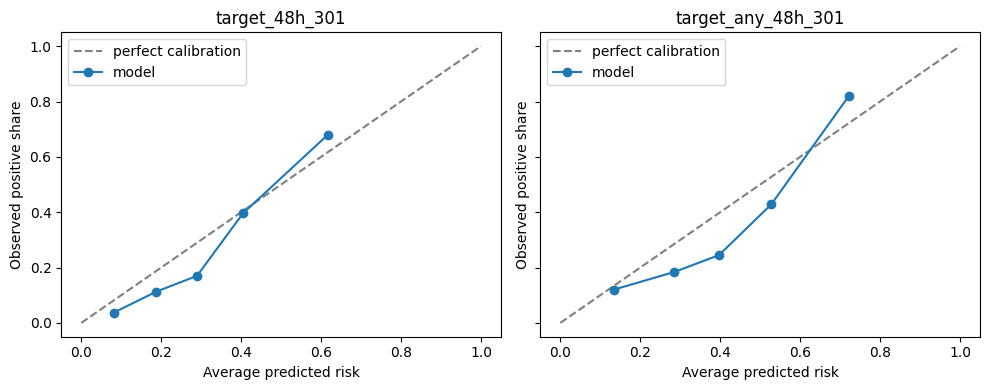

In [12]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

calibration_fig, calibration_axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
primary_labels = ["target_48h_301", "target_any_48h_301"]
for ax, label in zip(calibration_axes, primary_labels):
    predictions = rolling_predictions[label]
    observed_rate, mean_risk = calibration_curve(
        predictions["actual"], predictions["risk"], n_bins=5, strategy="quantile"
    )
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="perfect calibration")
    ax.plot(mean_risk, observed_rate, marker="o", label="model")
    ax.set_title(label)
    ax.set_xlabel("Average predicted risk")
    ax.set_ylabel("Observed positive share")
    ax.legend()
calibration_fig.tight_layout()
plt.show()


In [13]:
compact = ["AQI", "season_day", "AT (°C)", "RH (%)", "WS (m/s)"]

def oof_predictions(cols, label):
    """Risk for every held-out day, from models that never saw that winter."""
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(C=0.1, max_iter=1000))
    parts = []
    for w in winters:
        tr = rows_of(label, [x for x in winters if x != w])
        te = rows_of(label, [w]).copy()
        te["risk"] = clone(model).fit(tr[cols], tr[label]).predict_proba(te[cols])[:, 1]
        parts.append(te)
    return pd.concat(parts)

def alert_row(oof, label, alert, name):
    pos = oof[label] == 1
    caught = int((alert & pos).sum())
    return {"alert rule": name, "alerts": int(alert.sum()), "positive forecast days caught": caught,
            "positive forecast days missed": int((~alert & pos).sum()), "false alarms": int((alert & ~pos).sum()),
            "alert precision": round(caught / max(int(alert.sum()), 1), 2),
            "positive forecast days caught (share)": round(caught / pos.sum(), 2)}

for label in labels:
    oof = oof_predictions(compact, label)
    rows = [alert_row(oof, label, oof["risk"] >= t, f"risk >= {t}") for t in [0.2, 0.3, 0.4, 0.5, 0.6]]
    rows.append(alert_row(oof, label, oof["AQI"] >= 250, "simple rule: AQI >= 250"))
    print(f"\n=== {label} === ({len(oof)} held-out days, {int(oof[label].sum())} positive forecast days)")
    print(pd.DataFrame(rows).to_string(index=False))

# Event-level and starting-AQI-band view using chronological predictions.
label, thr = "target_any_48h_301", 0.4
chron = rolling_predictions[label].join(daily_4pm[["AQI"]], how="left")

def winter_start_year(timestamp):
    return timestamp.year if timestamp.month >= 11 else timestamp.year - 1

onsets_by_season = {}
for onset in onsets:
    onsets_by_season.setdefault(winter_start_year(onset), []).append(onset)
chronological_seasons = set(chron["season"].astype(int))

covered_events, caught_events, first_lead_hours = [], [], []
for onset in onsets:
    season = winter_start_year(onset)
    if season not in chronological_seasons:
        continue
    window = chron.loc[(chron.index >= onset - pd.Timedelta(hours=48)) &
                       (chron.index < onset)]
    if len(window):
        covered_events.append(onset)
        warning_times = window.index[window["risk"] >= thr]
        if len(warning_times):
            caught_events.append(onset)
            first_lead_hours.append((onset - warning_times.min()).total_seconds() / 3600)

print(f"\nChronological evaluation through winter 2024-25; {label}, cutoff {thr}")
print(f"Onsets with a usable forecast window: {len(covered_events)}")
print(f"Unique onsets warned before: {len(caught_events)}; missed among covered: {len(covered_events) - len(caught_events)}")
if first_lead_hours:
    print(f"Median lead from first warning: {np.median(first_lead_hours):.1f} hours")

# Group alert forecast days into one warning episode when their 48h windows overlap.
warning_episodes = false_warning_episodes = 0
for season, group in chron.loc[chron["risk"] >= thr].groupby("season"):
    alert_times = list(group.index.sort_values())
    episodes, current_episode = [], [alert_times[0]]
    for alert_time in alert_times[1:]:
        if alert_time - current_episode[-1] <= pd.Timedelta(hours=48):
            current_episode.append(alert_time)
        else:
            episodes.append(current_episode)
            current_episode = [alert_time]
    episodes.append(current_episode)
    season_onsets = onsets_by_season.get(int(season), [])
    for episode in episodes:
        warning_episodes += 1
        matched = any(
            any(pd.Timedelta(0) < onset - alert_time <= pd.Timedelta(hours=48)
                for alert_time in episode)
            for onset in season_onsets
        )
        false_warning_episodes += int(not matched)
print(f"Warning episodes: {warning_episodes}; episodes with no onset in their forecast windows: {false_warning_episodes}")

chron["band"] = pd.cut(chron["AQI"], [0, 200, 250, 301], right=False,
                       labels=["<200", "200-249", "250-300"])
chron["alert"] = chron["risk"] >= thr
print(chron.groupby("band", observed=True).agg(
    days=("risk", "size"), positive_forecast_days=("actual", "sum"),
    alerts=("alert", "sum")
).to_string())



=== target_24h_301 === (310 held-out days, 59 positive forecast days)
             alert rule  alerts  positive forecast days caught  positive forecast days missed  false alarms  alert precision  positive forecast days caught (share)
            risk >= 0.2     118                             50                              9            68             0.42                                   0.85
            risk >= 0.3      77                             41                             18            36             0.53                                   0.69
            risk >= 0.4      42                             30                             29            12             0.71                                   0.51
            risk >= 0.5      21                             16                             43             5             0.76                                   0.27
            risk >= 0.6       6                              4                             55             2  

## Winter 2020–21 inclusion sensitivity

January–February 2021 official CPCB AQI is flagged because it disagreed with a PM-derived proxy; that discrepancy does not establish the CPCB values are wrong. This sensitivity adds winter-start 2020 rows from the unmasked source to each training fold and keeps the held-out winters fixed. It does not use winter 2025–26. The primary model remains unchanged because this comparison is being made after the holdout was already evaluated; use these results to disclose sensitivity, not to retune the model or cutoffs.


In [14]:
# Sensitivity: add unmasked official AQI for winter 2020–21 to training only.
# The existing 2025–26 holdout is not used by this comparison.
sensitivity_cols = ["AQI", "season_day", "AT (°C)", "RH (%)", "WS (m/s)"]
sensitivity_source = pd.read_csv(
    "../processed_data/delhi_6station_avg_2018_2026.csv",
    index_col="Timestamp", parse_dates=True
).sort_index()
winter_2020 = sensitivity_source.loc[
    (sensitivity_source.index.hour == 16)
    & (sensitivity_source.index.minute == 0)
].copy()
winter_2020["season"] = np.where(
    winter_2020.index.month >= 11,
    winter_2020.index.year,
    winter_2020.index.year - 1
)
winter_2020 = winter_2020.loc[
    winter_2020.index.month.isin([11, 12, 1, 2])
    & winter_2020["season"].eq(2020)
].copy()
winter_start = pd.DatetimeIndex(pd.to_datetime(pd.DataFrame({
    "year": winter_2020["season"].astype(int).values,
    "month": 11,
    "day": 1
})))
winter_2020["season_day"] = (winter_2020.index - winter_start).days

for horizon in [24, 48, 72]:
    future = sensitivity_source["AQI"].shift(freq=f"-{horizon}h")
    future_col = f"AQI_at_plus_{horizon}h"
    winter_2020[future_col] = future.reindex(winter_2020.index)
    eligible = (winter_2020["AQI"].notna()
                & winter_2020["AQI"].lt(301)
                & winter_2020[future_col].notna())
    exact_col = f"target_{horizon}h_301"
    winter_2020[exact_col] = np.nan
    winter_2020.loc[eligible, exact_col] = winter_2020.loc[
        eligible, future_col
    ].ge(301).astype(float)

    any_col = f"target_any_{horizon}h_301"
    winter_2020[any_col] = np.nan
    for start_time in winter_2020.index[eligible]:
        window = sensitivity_source["AQI"].loc[
            start_time + pd.Timedelta(hours=1):
            start_time + pd.Timedelta(hours=horizon)
        ]
        if window.ge(301).any():
            winter_2020.loc[start_time, any_col] = 1.0
        elif len(window) == horizon and window.notna().all():
            winter_2020.loc[start_time, any_col] = 0.0

sensitivity_rows = pd.concat([daily_4pm, winter_2020]).sort_index()
compact_model = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(),
    LogisticRegression(C=0.1, max_iter=1000)
)
cv_winter_list = [2018, 2019, 2021, 2022, 2023, 2024]
sensitivity_table = []
oof_sensitivity = {}

def usable_sensitivity_rows(frame, label, season_list):
    return frame.loc[
        frame["season"].isin(season_list)
        & frame["AQI"].lt(301)
        & frame[label].notna()
    ]

for label in labels:
    y_parts, p_without, p_with, fold_auc_without, fold_auc_with = [], [], [], [], []
    for heldout in cv_winter_list:
        test_fold = usable_sensitivity_rows(daily_4pm, label, [heldout])
        train_without = usable_sensitivity_rows(
            daily_4pm, label, [w for w in cv_winter_list if w != heldout]
        )
        train_with = usable_sensitivity_rows(
            sensitivity_rows, label,
            [w for w in cv_winter_list if w != heldout] + [2020]
        )
        pred_without = clone(compact_model).fit(
            train_without[sensitivity_cols], train_without[label]
        ).predict_proba(test_fold[sensitivity_cols])[:, 1]
        pred_with = clone(compact_model).fit(
            train_with[sensitivity_cols], train_with[label]
        ).predict_proba(test_fold[sensitivity_cols])[:, 1]
        actual = test_fold[label].astype(int).to_numpy()
        y_parts.append(actual)
        p_without.extend(pred_without)
        p_with.extend(pred_with)
        fold_auc_without.append(
            roc_auc_score(actual, pred_without)
            if np.unique(actual).size == 2 else np.nan
        )
        fold_auc_with.append(
            roc_auc_score(actual, pred_with)
            if np.unique(actual).size == 2 else np.nan
        )
    actual = np.concatenate(y_parts)
    pred_without = np.asarray(p_without)
    pred_with = np.asarray(p_with)
    sensitivity_table.append({
        "outcome": label,
        "held-out days": len(actual),
        "positives": int(actual.sum()),
        "AP without/with": f"{average_precision_score(actual, pred_without):.3f} / {average_precision_score(actual, pred_with):.3f}",
        "AUC without/with": f"{roc_auc_score(actual, pred_without):.3f} / {roc_auc_score(actual, pred_with):.3f}",
        "Brier without/with": f"{brier_score_loss(actual, pred_without):.3f} / {brier_score_loss(actual, pred_with):.3f}",
        "worst-winter AUC without/with": f"{np.nanmin(fold_auc_without):.3f} / {np.nanmin(fold_auc_with):.3f}"
    })
    oof_sensitivity[label] = (actual, pred_without, pred_with)

print("Winter 2020–21 eligible rows by outcome:")
print(pd.DataFrame([
    {"outcome": label,
     "eligible days": int(usable_sensitivity_rows(winter_2020, label, [2020]).shape[0]),
     "positive days": int(usable_sensitivity_rows(winter_2020, label, [2020])[label].sum())}
    for label in labels
]).to_string(index=False))
print("\nSix-winter OOF compact-model sensitivity (2025–26 excluded):")
print(pd.DataFrame(sensitivity_table).to_string(index=False))

print("\nLocked 48h alert cutoffs on pooled OOF forecasts:")
for label, threshold in [("target_48h_301", 0.3), ("target_any_48h_301", 0.4)]:
    actual, pred_without, pred_with = oof_sensitivity[label]
    for name, risk in [("without winter 2020–21", pred_without),
                       ("with winter 2020–21", pred_with)]:
        alert = risk >= threshold
        caught = int((alert & (actual == 1)).sum())
        print(f"{label}, {name}, cutoff {threshold}: alerts={int(alert.sum())}, "
              f"caught={caught}/{int(actual.sum())} ({caught / actual.sum():.1%}), "
              f"false alarms={int((alert & (actual == 0)).sum())}")

print("\nWinter 2024–25 validation at the same locked cutoffs:")
for label, threshold in [("target_48h_301", 0.3), ("target_any_48h_301", 0.4)]:
    validation = usable_sensitivity_rows(daily_4pm, label, [2024])
    train_without = usable_sensitivity_rows(daily_4pm, label, [2018, 2019, 2021, 2022, 2023])
    train_with = usable_sensitivity_rows(sensitivity_rows, label, [2018, 2019, 2020, 2021, 2022, 2023])
    for name, train_rows in [("without winter 2020–21", train_without),
                             ("with winter 2020–21", train_with)]:
        risk = clone(compact_model).fit(
            train_rows[sensitivity_cols], train_rows[label]
        ).predict_proba(validation[sensitivity_cols])[:, 1]
        y_val = validation[label].astype(int).to_numpy()
        alert = risk >= threshold
        caught = int((alert & (y_val == 1)).sum())
        auc = roc_auc_score(y_val, risk) if np.unique(y_val).size == 2 else np.nan
        print(f"{label}, {name}: AP={average_precision_score(y_val, risk):.3f}, "
              f"AUC={auc:.3f}, Brier={brier_score_loss(y_val, risk):.3f}, "
              f"alerts={int(alert.sum())}, caught={caught}/{int(y_val.sum())}, "
              f"false alarms={int((alert & (y_val == 0)).sum())}")


Winter 2020–21 eligible rows by outcome:
           outcome  eligible days  positive days
    target_24h_301             44             14
    target_48h_301             44             23
    target_72h_301             43             24
target_any_24h_301             44             19
target_any_48h_301             44             29
target_any_72h_301             43             35

Six-winter OOF compact-model sensitivity (2025–26 excluded):
           outcome  held-out days  positives AP without/with AUC without/with Brier without/with worst-winter AUC without/with
    target_24h_301            310         59   0.600 / 0.606    0.868 / 0.870      0.109 / 0.110                 0.803 / 0.827
    target_48h_301            310         94   0.738 / 0.732    0.854 / 0.846      0.140 / 0.144                 0.794 / 0.779
    target_72h_301            310        104   0.758 / 0.754    0.856 / 0.853      0.146 / 0.149                 0.762 / 0.759
target_any_24h_301            299         66  

## Locked model, primary outcome, and alert cutoffs

**Model:** logistic regression with `C=0.1` using `AQI`, `season_day`, `AT (°C)`, `RH (%)`, and `WS (m/s)`. **Primary outcome:** `target_48h_301` (exact +48h crossing, starting below 301). The key secondary outcome is `target_any_48h_301`; the 24h and 72h outcomes are exploratory secondary results.

The compact model was selected for parsimony after comparing cross-winter scores. The comparisons do not include paired uncertainty tests, so they do not establish statistical equivalence to the all-columns model.

The 2025–26 model and cutoffs remain fixed: 0.3 for the exact +48h outcome and 0.4 for the any-hour +48h outcome. The historical rule chose the highest cutoff that captured at least 80% of **positive forecast days**, not 80% of unique onsets. At 0.4, the expanded six-winter any-hour table now captures 77% of positive forecast days; report this without retuning. Only the two +48h outcomes have locked alert cutoffs. Cell A is exploratory; Cell B reports the test results as saved, without changing the model or cutoffs.


## Cell A — exploratory alert-band results

Cross-winter analysis only; this does not use the sealed test winter.

In [15]:
# Cell A — caught positive forecast days by starting AQI band
final_cols = ["AQI", "season_day", "AT (°C)", "RH (%)", "WS (m/s)"]
locked_thr = {"target_48h_301": 0.3, "target_any_48h_301": 0.4}

def band_table(df, label, thr):
    df = df.copy()
    df["alert"] = df["risk"] >= thr
    df["hit"] = df["alert"] & (df[label] == 1)
    df["band"] = pd.cut(df["AQI"], [0, 200, 250, 301], right=False,
                        labels=["<200", "200-249", "250-300"])
    return df.groupby("band", observed=True).agg(days=("risk", "size"), positive_forecast_days=(label, "sum"),
                                                 alerts=("alert", "sum"), positive_days_caught=("hit", "sum"))

for label, thr in locked_thr.items():
    print(f"\n{label} (cutoff {thr})")
    print(band_table(oof_predictions(final_cols, label), label, thr).to_string())



target_48h_301 (cutoff 0.3)
         days  positive_forecast_days  alerts  positive_days_caught
band                                                               
<200       98                    12.0      14                     5
200-249    83                    16.0      32                    12
250-300   129                    66.0      96                    61

target_any_48h_301 (cutoff 0.4)
         days  positive_forecast_days  alerts  positive_days_caught
band                                                               
<200       88                    13.0       8                     4
200-249    77                    25.0      32                    17
250-300   126                    75.0     100                    66


## Cell B — sealed test winter 2025–26

This reports scores for all six outcome/horizon combinations, with alert rules only for the locked +48h outcomes. The onset-oriented test contains only 28 eligible forecast days and 11 onsets with a usable window. Adjacent test days are correlated, so the saved day-resampling ranges are approximate. Do not tune the model, cutoffs, or primary outcome from these results.


In [16]:
# Cell B: evaluate the six horizon/outcome pairs on winter 2025-26.
test_onsets = onsets[(onsets >= "2025-11-01") & (onsets < "2026-03-01")]
rng = np.random.default_rng(0)

for label in labels:
    tr = rows_of(label, winters)
    te = rows_for(label, test_rows).copy()
    if tr.empty or te.empty:
        print(f"\n=== TEST {label} === no eligible training or test rows; skipped")
        continue
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                          LogisticRegression(C=0.1, max_iter=1000))
    te["risk"] = model.fit(tr[final_cols], tr[label]).predict_proba(te[final_cols])[:, 1]
    y, p = te[label].astype(int).values, te["risk"].values

    # Day-resampling ranges are approximate; consecutive days are correlated.
    aps, aucs = [], []
    for _ in range(1000):
        i = rng.integers(0, len(y), len(y))
        if np.unique(y[i]).size == 2:
            aps.append(average_precision_score(y[i], p[i]))
            aucs.append(roc_auc_score(y[i], p[i]))
    ap = average_precision_score(y, p) if y.sum() else np.nan
    auc = roc_auc_score(y, p) if np.unique(y).size == 2 else np.nan
    ap_range = (f"{np.percentile(aps, 2.5):.2f}-{np.percentile(aps, 97.5):.2f}"
                if aps else "not estimable")
    auc_range = (f"{np.percentile(aucs, 2.5):.2f}-{np.percentile(aucs, 97.5):.2f}"
                 if aucs else "not estimable")
    ref = brier_score_loss(y, np.full(len(y), tr[label].mean()))
    print(f"\n=== TEST {label} === {len(te)} eligible days, {int(y.sum())} positive forecast days")
    print(f"avg precision {ap:.2f} (day-resampling range {ap_range}, reference {y.mean():.2f})")
    print(f"ROC AUC {auc:.2f} (day-resampling range {auc_range})")
    print(f"Brier {brier_score_loss(y, p):.3f} (training-prevalence reference {ref:.3f})")

    # The 0.3 / 0.4 thresholds were locked for the two 48h outcomes only.
    if label in locked_thr:
        thr = locked_thr[label]
        print(pd.DataFrame([alert_row(te, label, te["risk"] >= thr, f"model, risk >= {thr}"),
                            alert_row(te, label, te["AQI"] >= 250, "simple rule: AQI >= 250")]).to_string(index=False))
        if label == "target_any_48h_301":
            window_hits = [(te.loc[(te.index >= o - pd.Timedelta(hours=48)) &
                                   (te.index < o), "risk"] >= thr) for o in test_onsets]
            window_hits = [w for w in window_hits if len(w)]
            print(f"onsets with a forecast: {len(window_hits)}; warned in advance: {sum(w.any() for w in window_hits)}")
        print(band_table(te, label, thr).to_string())



=== TEST target_24h_301 === 28 eligible days, 12 positive forecast days
avg precision 0.52 (day-resampling range 0.28-0.77, reference 0.43)
ROC AUC 0.51 (day-resampling range 0.27-0.74)
Brier 0.274 (training-prevalence reference 0.302)

=== TEST target_48h_301 === 28 eligible days, 19 positive forecast days
avg precision 0.77 (day-resampling range 0.56-0.94, reference 0.68)
ROC AUC 0.60 (day-resampling range 0.34-0.82)
Brier 0.291 (training-prevalence reference 0.359)
             alert rule  alerts  positive forecast days caught  positive forecast days missed  false alarms  alert precision  positive forecast days caught (share)
     model, risk >= 0.3      17                             12                              7             5             0.71                                   0.63
simple rule: AQI >= 250      19                             13                              6             6             0.68                                   0.68
         days  positive_forecast_d

In [17]:
for label in labels:
    oof = oof_predictions(final_cols, label)
    print(f"\n{label}")
    print(oof.groupby("season").agg(days=("risk", "size"), actual_rate=(label, "mean"),
                                    mean_risk=("risk", "mean")).round(2).to_string())



target_24h_301
        days  actual_rate  mean_risk
season                              
2018      44         0.30       0.20
2019      65         0.15       0.18
2021      53         0.21       0.20
2022      54         0.20       0.21
2023      35         0.20       0.21
2024      59         0.12       0.18

target_48h_301
        days  actual_rate  mean_risk
season                              
2018      44         0.45       0.38
2019      65         0.28       0.30
2021      53         0.30       0.33
2022      54         0.31       0.32
2023      35         0.29       0.31
2024      59         0.22       0.23

target_72h_301
        days  actual_rate  mean_risk
season                              
2018      44         0.48       0.44
2019      65         0.32       0.34
2021      53         0.32       0.37
2022      54         0.35       0.35
2023      35         0.31       0.32
2024      59         0.25       0.25

target_any_24h_301
        days  actual_rate  mean_risk
season 

In [18]:
# Descriptive day-level state check; these are forecast rows, not unique onset events.
d = daily_4pm[daily_4pm["AQI"].notna() & daily_4pm["AQI_at_plus_48h"].notna()].copy()
d["high_now"] = d["AQI"] >= 301
d["high_48h"] = d["AQI_at_plus_48h"] >= 301
d["already_high"] = d["high_now"] & d["high_48h"]
d["high_now_cleared"] = d["high_now"] & ~d["high_48h"]
d["below_now_high_48h"] = ~d["high_now"] & d["high_48h"]

print(pd.crosstab(d["high_now"], d["high_48h"],
                  rownames=["AQI >= 301 now"], colnames=["AQI >= 301 in 48h"]))

stay = int(d["already_high"].sum())
print("\nHigh now -> still high in 48h:", round(stay / d["high_now"].sum(), 2))
print("High in 48h -> was already high now:", round(stay / d["high_48h"].sum(), 2))
print("Below 301 now -> high at +48h (forecast-day rate):",
      round(int(d["below_now_high_48h"].sum()) / int((~d["high_now"]).sum()), 2))

by_winter = d.groupby("season").agg(
    days=("AQI", "size"),
    high_in_48h=("high_48h", "sum"),
    already_high=("already_high", "sum"),
    high_now_cleared=("high_now_cleared", "sum"),
    below_now_high_at_48h=("below_now_high_48h", "sum")
)
print("\n", by_winter.to_string())


AQI >= 301 in 48h  False  True 
AQI >= 301 now                 
False                225    113
True                 125    377

High now -> still high in 48h: 0.75
High in 48h -> was already high now: 0.77
Below 301 now -> high at +48h (forecast-day rate): 0.33

         days  high_in_48h  already_high  high_now_cleared  below_now_high_at_48h
season                                                                          
2018     120           74            54                22                     20
2019     121           54            36                20                     18
2021     120           66            50                17                     16
2022     120           64            47                19                     17
2023     121           84            74                12                     10
2024     120           59            46                15                     13
2025     118           89            70                20                     19


## Rainfall in the next 48 hours: descriptive diagnostic

This compares realized station-average rainfall (`RF`) during the 48 hours after each forecast time with the AQI change at the exact +48h endpoint. It is descriptive only: future rainfall is not known at 4 PM unless supplied by a rainfall forecast. The cell requires at least 40 of 48 rainfall hours to be observed and includes all usable winters in `daily_4pm`, including 2025–26. Current files produce 840 usable rows; the earlier 781-row summary does not reproduce and must be reconciled before publication. The outputs report means and medians separately. `TOT-RF` is not used. This is descriptive: realized future rainfall is unavailable at forecast time and does not establish a causal effect.


In [19]:
import numpy as np
import pandas as pd

hourly_full = pd.read_csv("../processed_data/delhi_6station_avg_2018_2026_cleaned.csv",
                          index_col=0, parse_dates=True)
rf = hourly_full["RF (mm)"]

def rain_next48(t):
    window = rf.loc[t + pd.Timedelta(hours=1):t + pd.Timedelta(hours=48)]
    return window.sum() if window.notna().sum() >= 40 else np.nan

daily_4pm["rain_next48_mm"] = [rain_next48(t) for t in daily_4pm.index]
daily_4pm["rain_bin"] = pd.cut(
    daily_4pm["rain_next48_mm"], [-0.01, 0, 1, 5, 1000],
    labels=["none", "under 1 mm", "1-5 mm", "over 5 mm"]
)

r = daily_4pm[
    daily_4pm[["AQI", "AQI_at_plus_48h", "rain_next48_mm"]].notna().all(axis=1)
].copy()
r["change"] = r["AQI_at_plus_48h"] - r["AQI"]

print(f"Usable forecast days: {len(r)}")
print("Usable days by winter:")
print(r.groupby("season").size().to_string())
print("\nRain-bin counts:")
print(r["rain_bin"].value_counts(sort=False, dropna=False).to_string())
nonzero_rain = int(r["rain_next48_mm"].gt(0).sum())
one_mm_or_more = int(r["rain_next48_mm"].ge(1).sum())
print(f"Nonzero rain: {nonzero_rain}/{len(r)} ({nonzero_rain / len(r):.1%}); "
      f"at least 1 mm: {one_mm_or_more}/{len(r)} ({one_mm_or_more / len(r):.1%})")

print("\nStart at AQI 301 or above")
print(r[r["AQI"] >= 301].groupby("rain_bin", observed=True).agg(
    days=("change", "size"),
    cleared_share=("AQI_at_plus_48h", lambda values: (values < 301).mean()),
    mean_change=("change", "mean"),
    median_change=("change", "median")
).round(2).to_string())

print("\nStart below AQI 301")
print(r[r["AQI"] < 301].groupby("rain_bin", observed=True).agg(
    days=("change", "size"),
    became_high_share=("AQI_at_plus_48h", lambda values: (values >= 301).mean()),
    mean_change=("change", "mean"),
    median_change=("change", "median")
).round(2).to_string())


Usable forecast days: 840
Usable days by winter:
season
2018    120
2019    121
2021    120
2022    120
2023    121
2024    120
2025    118

Rain-bin counts:
rain_bin
none          707
under 1 mm     95
1-5 mm         29
over 5 mm       9
Nonzero rain: 133/840 (15.8%); at least 1 mm: 38/840 (4.5%)

Start at AQI 301 or above
            days  cleared_share  mean_change  median_change
rain_bin                                                   
none         431           0.19       -16.29          -13.0
under 1 mm    52           0.50       -69.54          -64.5
1-5 mm        14           0.79      -129.43         -145.5
over 5 mm      5           0.80      -128.40         -134.0

Start below AQI 301
            days  became_high_share  mean_change  median_change
rain_bin                                                       
none         276               0.37        39.30           41.5
under 1 mm    43               0.16        -2.49          -11.0
1-5 mm        15               0.20  

In [20]:
# Post-hoc secondary exit task: from AQI 301+, will it be below 301 exactly 48 hours later?
test_season = 2025                       # winter 2025-26; exploratory test for this post-hoc task
daily_4pm["clear_48h"] = np.where(
    daily_4pm["AQI"].ge(301) & daily_4pm["AQI_at_plus_48h"].notna(),
    (daily_4pm["AQI_at_plus_48h"] < 301).astype(float), np.nan)

exit_use = daily_4pm[daily_4pm["clear_48h"].notna()]
new_model = lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                  LogisticRegression(C=0.1, max_iter=1000))

def exit_cv(cols):
    ps, ys, aucs = [], [], []
    for w in winters:
        tr = exit_use[exit_use["season"].isin([x for x in winters if x != w])]
        te = exit_use[exit_use["season"] == w]
        p = new_model().fit(tr[cols], tr["clear_48h"]).predict_proba(te[cols])[:, 1]
        ps.append(p); ys.append(te["clear_48h"].values)
        aucs.append(roc_auc_score(te["clear_48h"], p) if te["clear_48h"].nunique() == 2 else np.nan)
    p_all, y_all = np.concatenate(ps), np.concatenate(ys)
    return {"avg precision": round(average_precision_score(y_all, p_all), 2),
            "ROC AUC": round(roc_auc_score(y_all, p_all), 2),
            "Brier": round(brier_score_loss(y_all, p_all), 3),
            "worst winter AUC": round(np.nanmin(aucs), 2)}

dev = exit_use[exit_use["season"].isin(winters)]
print(f"Development winters: {len(dev)} days start at 301+ with a known outcome; "
      f"{int(dev['clear_48h'].sum())} cleared (reference average precision {dev['clear_48h'].mean():.2f})")
exit_table = pd.DataFrame([{"columns used": name, **exit_cv(cols)} for name, cols in
                           {"AQI only": ["AQI"], "AQI + time of winter": base,
                            "compact (AQI, season, temp, humidity, wind)": final_cols,
                            "all columns": all_features}.items()])
print(exit_table.to_string(index=False))

# Test the post-hoc exit task on winter 2025-26; interpret as exploratory
tr, te = exit_use[exit_use["season"].isin(winters)], exit_use[exit_use["season"] == test_season]
p = new_model().fit(tr[final_cols], tr["clear_48h"]).predict_proba(te[final_cols])[:, 1]
y = te["clear_48h"].values
rng = np.random.default_rng(0)
boot = [rng.integers(0, len(y), len(y)) for _ in range(1000)]
aucs = [roc_auc_score(y[i], p[i]) for i in boot if y[i].min() != y[i].max()]
print(f"\nPOST-HOC TEST winter {test_season} (exploratory): {len(y)} days, {int(y.sum())} cleared, "
      f"AUC {roc_auc_score(y, p):.2f} (range {np.percentile(aucs, 2.5):.2f}-{np.percentile(aucs, 97.5):.2f}), "
      f"AP {average_precision_score(y, p):.2f} (reference {y.mean():.2f}), "
      f"Brier {brier_score_loss(y, p):.3f}, mean risk {p.mean():.2f} vs actual {y.mean():.2f}")

Development winters: 412 days start at 301+ with a known outcome; 105 cleared (reference average precision 0.25)
                               columns used  avg precision  ROC AUC  Brier  worst winter AUC
                                   AQI only           0.36     0.64  0.182              0.57
                       AQI + time of winter           0.44     0.69  0.173              0.60
compact (AQI, season, temp, humidity, wind)           0.53     0.74  0.160              0.60
                                all columns           0.55     0.75  0.160              0.63

POST-HOC TEST winter 2025 (exploratory): 90 days, 20 cleared, AUC 0.80 (range 0.69-0.90), AP 0.57 (reference 0.22), Brier 0.133, mean risk 0.24 vs actual 0.22


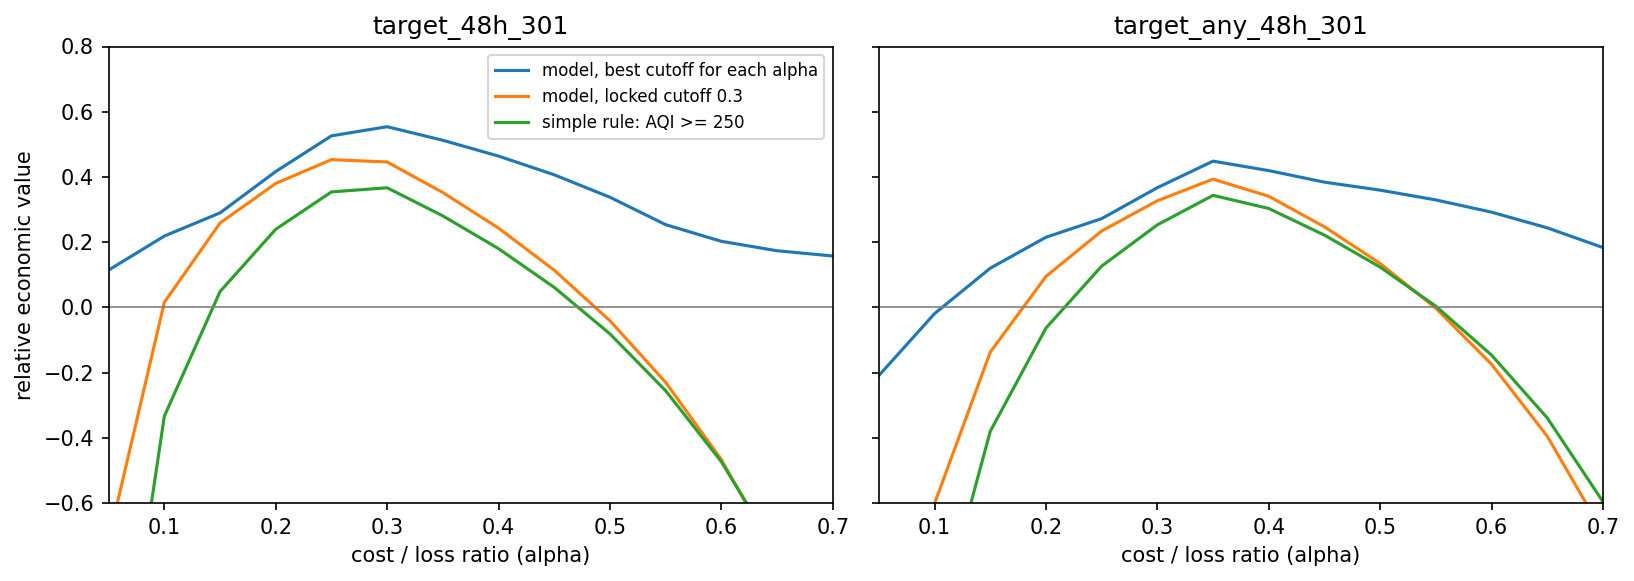

           outcome  alpha  model best cutoff  model locked cutoff  rule AQI>=250
    target_48h_301    0.1               0.22                 0.02          -0.33
    target_48h_301    0.2               0.42                 0.38           0.24
    target_48h_301    0.3               0.55                 0.45           0.37
    target_48h_301    0.5               0.34                -0.04          -0.08
target_any_48h_301    0.1              -0.02                -0.60          -1.01
target_any_48h_301    0.2               0.22                 0.09          -0.06
target_any_48h_301    0.3               0.37                 0.33           0.25
target_any_48h_301    0.5               0.36                 0.13           0.12


In [24]:
# Relative economic value (REV): how useful is an alert for people with different cost/loss trade-offs?
# alpha = cost of taking protective action / loss if the event happens unprotected (0 to 1).
import os
import matplotlib.pyplot as plt
os.makedirs("../results", exist_ok=True)
alphas = np.round(np.arange(0.05, 0.96, 0.05), 2)

def rev_curve(alert, event):
    event, alert = np.asarray(event).astype(bool), np.asarray(alert).astype(bool)
    s = event.mean()
    hit = (alert & event).sum() / event.sum()
    fa = (alert & ~event).sum() / (~event).sum()
    out = []
    for a in alphas:
        e_forecast = a * (hit * s + fa * (1 - s)) + (1 - hit) * s
        e_climate = min(a, s)
        e_perfect = a * s
        out.append((e_climate - e_forecast) / (e_climate - e_perfect) if e_climate > e_perfect else np.nan)
    return np.array(out)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
rev_rows = []
for ax, label in zip(axes, ["target_48h_301", "target_any_48h_301"]):
    chron = rolling_predictions[label].join(daily_4pm[["AQI"]], how="left")
    y = chron["actual"].values
    cutoffs = np.round(np.arange(0.05, 0.96, 0.05), 2)
    curves = np.array([rev_curve(chron["risk"].values >= c, y) for c in cutoffs])
    best = np.nanmax(curves, axis=0)                                  # best cutoff for each alpha
    locked = rev_curve(chron["risk"].values >= locked_thr[label], y)  # the cutoff chosen in advance
    rule = rev_curve(chron["AQI"].values >= 250, y)                   # simple rule: AQI >= 250
    ax.plot(alphas, best, label="model, best cutoff for each alpha")
    ax.plot(alphas, locked, label=f"model, locked cutoff {locked_thr[label]}")
    ax.plot(alphas, rule, label="simple rule: AQI >= 250")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(label); ax.set_xlabel("cost / loss ratio (alpha)")
    for a in [0.1, 0.2, 0.3, 0.5]:
        i = int(np.where(alphas == a)[0][0])
        rev_rows.append({"outcome": label, "alpha": a, "model best cutoff": round(best[i], 2),
                         "model locked cutoff": round(locked[i], 2), "rule AQI>=250": round(rule[i], 2)})
axes[0].set_ylabel("relative economic value")
axes[0].legend(fontsize=8)
for ax in axes:
    ax.set_ylim(-0.6, 0.8)
    ax.set_xlim(0.05, 0.7)
fig.tight_layout()
fig.savefig("../results/rev_curves.png", dpi=150, bbox_inches="tight")
plt.show()
rev_table = pd.DataFrame(rev_rows)
print(rev_table.to_string(index=False))
rev_table.to_csv("../results/rev_table.csv", index=False)

In [22]:
# ORACLE experiment: what if the next 48 hours of rain were known at 4 PM?
# Not a real forecast. It only measures how much a good rainfall forecast could be worth.
daily_4pm["rain_log"] = np.log1p(daily_4pm["rain_next48_mm"])     # rain is very skewed, so use a log scale
with_rain = final_cols + ["rain_log"]
exit_use = daily_4pm[daily_4pm["clear_48h"].notna()]      # refresh so it includes the new rain column

print("ONSET (start below 301), leave-one-winter-out")
for label in ["target_48h_301", "target_any_48h_301"]:
    print(f"\n{label}")
    print(pd.DataFrame([{"columns used": "compact (no rain)", **winter_cv(final_cols, label)},
                        {"columns used": "compact + next-48h rain (oracle)", **winter_cv(with_rain, label)}]).to_string(index=False))

print("\nEXIT (start at 301+), leave-one-winter-out")
print(pd.DataFrame([{"columns used": "compact (no rain)", **exit_cv(final_cols)},
                    {"columns used": "compact + next-48h rain (oracle)", **exit_cv(with_rain)}]).to_string(index=False))

ONSET (start below 301), leave-one-winter-out

target_48h_301
                    columns used  avg precision  ROC AUC  Brier  worst winter AUC
               compact (no rain)           0.74     0.85  0.140              0.79
compact + next-48h rain (oracle)           0.73     0.85  0.141              0.79

target_any_48h_301
                    columns used  avg precision  ROC AUC  Brier  worst winter AUC
               compact (no rain)           0.77     0.81  0.171              0.71
compact + next-48h rain (oracle)           0.76     0.81  0.171              0.71

EXIT (start at 301+), leave-one-winter-out
                    columns used  avg precision  ROC AUC  Brier  worst winter AUC
               compact (no rain)           0.53     0.74  0.160              0.60
compact + next-48h rain (oracle)           0.62     0.80  0.145              0.66


In [23]:
import os, json, joblib, sys, sklearn, datetime
os.makedirs("../models", exist_ok=True)
freeze_winters = sorted(set(winters + [test_season]))               # every winter we have
frozen = {}
for label in ["target_48h_301", "target_any_48h_301"]:
    sub = daily_4pm[daily_4pm["season"].isin(freeze_winters) & daily_4pm["AQI"].lt(301)
                    & daily_4pm[label].notna()]
    frozen[label] = new_model().fit(sub[final_cols], sub[label])
    print(label, "trained on", len(sub), "days")
sub = daily_4pm[daily_4pm["season"].isin(freeze_winters) & daily_4pm["clear_48h"].notna()]
frozen["clear_48h"] = new_model().fit(sub[final_cols], sub["clear_48h"])
print("clear_48h trained on", len(sub), "days")

joblib.dump(frozen, "../models/frozen_models.joblib")
json.dump({"frozen_on": str(datetime.date.today()), "features": final_cols, "cutoffs": locked_thr,
           "trained_on_winters": freeze_winters, "sklearn_version": sklearn.__version__,
           "python_version": sys.version.split()[0],
           "note": "Research prototype. Not an operational warning system."},
          open("../models/frozen_models.json", "w"), indent=2)

def predict_risk(aqi, date, temp_c, rh_pct, wind_ms):
    """4 PM reading in, 48-hour outlook out. Below 301: risk of reaching 301. At 301+: chance of clearing."""
    date = pd.Timestamp(date)
    start_year = date.year if date.month >= 11 else date.year - 1
    row = pd.DataFrame([{"AQI": aqi, "season_day": (date - pd.Timestamp(start_year, 11, 1)).days,
                         "AT (°C)": temp_c, "RH (%)": rh_pct, "WS (m/s)": wind_ms}])[final_cols]
    if aqi < 301:
        return {"state": "below 301",
                "risk of reaching 301 exactly at +48h": round(float(frozen["target_48h_301"].predict_proba(row)[0, 1]), 2),
                "risk of reaching 301 at any hour within 48h": round(float(frozen["target_any_48h_301"].predict_proba(row)[0, 1]), 2)}
    return {"state": "301 or above",
            "chance of being below 301 at +48h": round(float(frozen["clear_48h"].predict_proba(row)[0, 1]), 2)}

print(predict_risk(240, "2026-11-10", 18, 55, 1.0))
print(predict_risk(350, "2026-11-10", 18, 55, 1.0))

target_48h_301 trained on 338 days
target_any_48h_301 trained on 319 days
clear_48h trained on 502 days
{'state': 'below 301', 'risk of reaching 301 exactly at +48h': 0.76, 'risk of reaching 301 at any hour within 48h': 0.8}
{'state': '301 or above', 'chance of being below 301 at +48h': 0.14}
